In [5]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


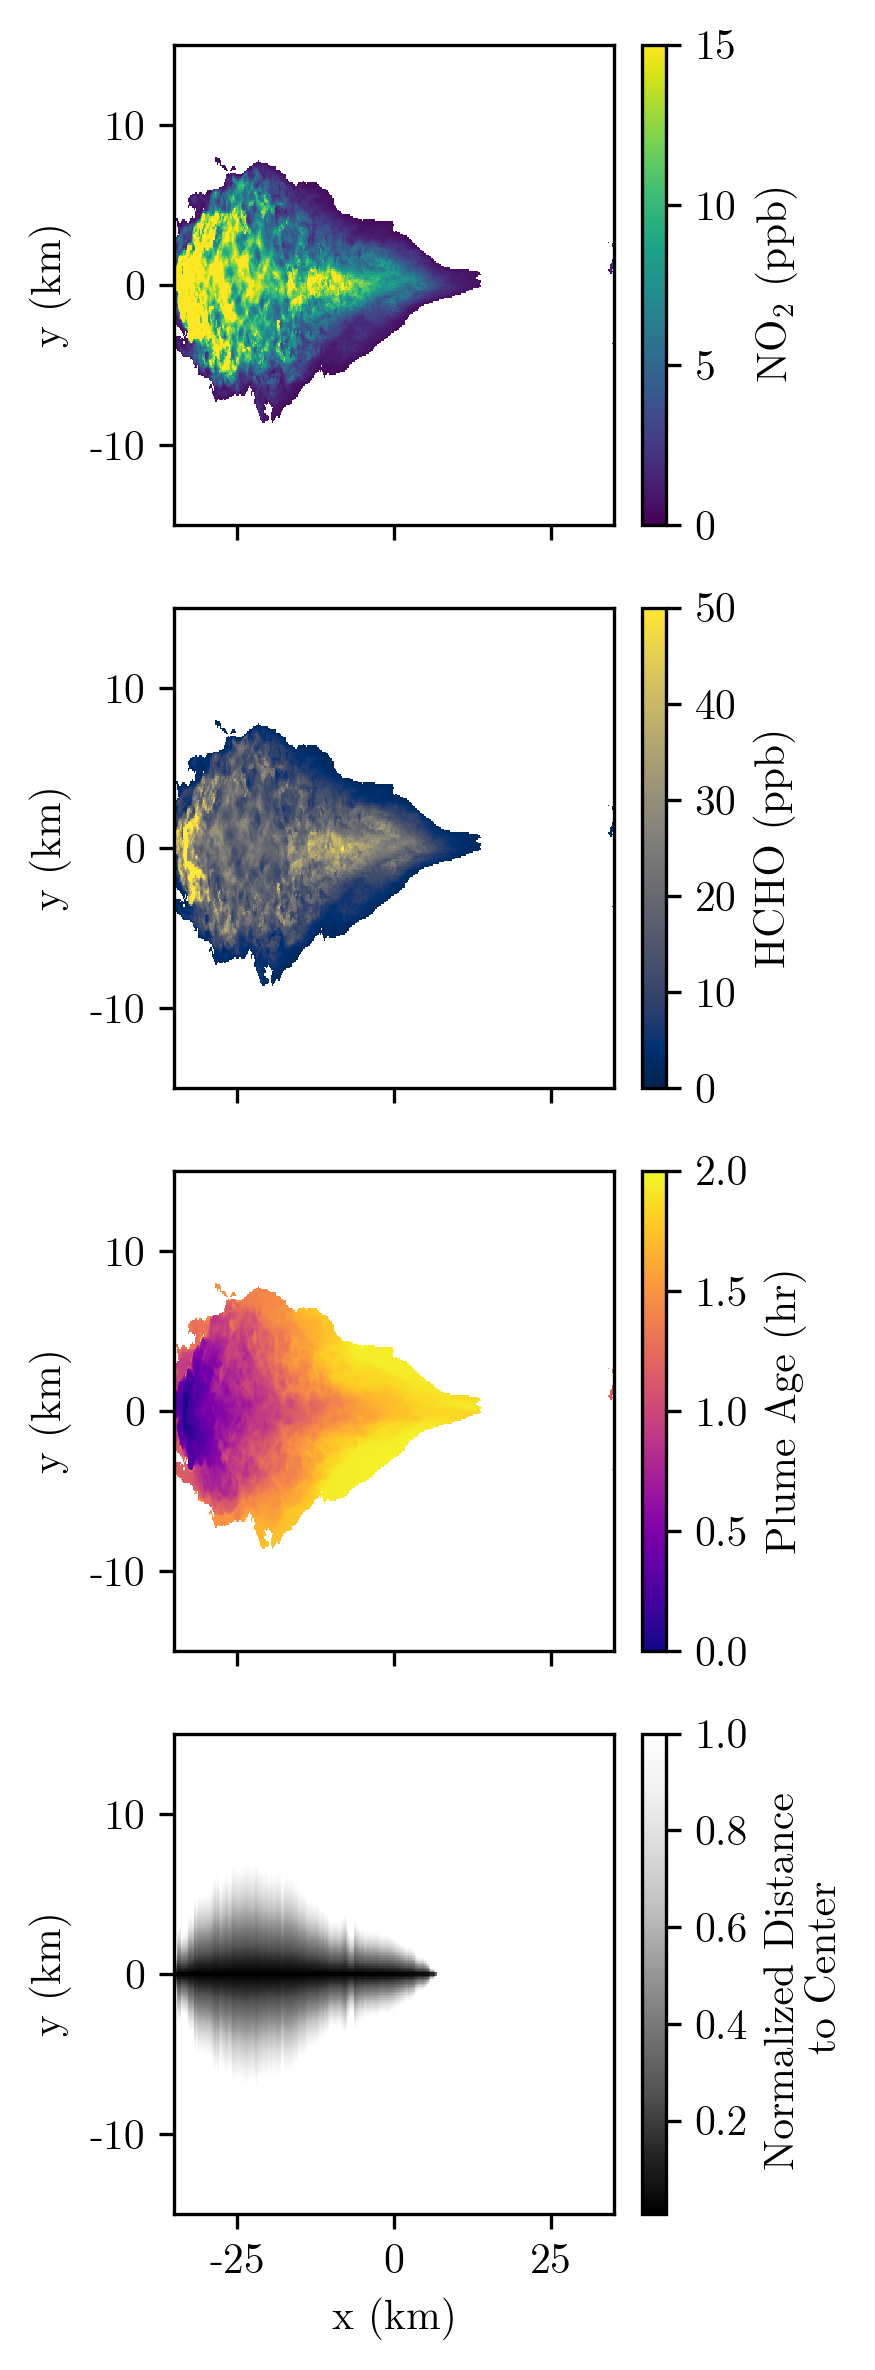

In [6]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

LES_DATASET = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data/les_williams.nc")
ds = xr.open_dataset(LES_DATASET)
needed = ["no2_plume_ppb", "hcho_plume_ppb", "plume_age", "normalized_distance_to_center"]
missing = [name for name in needed if name not in ds]
if missing:
    raise FileNotFoundError(", ".join(missing) + " missing from " + LES_DATASET.name)

def to_km(values):
    values = np.asarray(values, dtype=float)
    return values / 1000.0 if np.nanmax(np.abs(values)) > 100 else values

x_km = to_km(ds["x"].values if "x" in ds.coords else np.arange(ds.sizes["x"]))
y_km = to_km(ds["y"].values if "y" in ds.coords else np.arange(ds.sizes["y"]))
panels = [
    (ds["no2_plume_ppb"], "viridis", 0, 15, r"NO$_2$ (ppb)"),
    (ds["hcho_plume_ppb"], "cividis", 0, 50, "HCHO (ppb)"),
    (ds["plume_age"] / 3600.0, "plasma", 0, 2, "Plume Age (hr)"),
    (ds["normalized_distance_to_center"], "Greys_r", None, None, "Normalized Distance \n to Center"),
]
fig, axes = plt.subplots(4, 1, figsize=(3, 8), dpi=300, sharex=True)
for ax, (field, cmap, vmin, vmax, label) in zip(axes, panels):
    mesh = ax.pcolormesh(x_km, y_km, field, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
    fig.colorbar(mesh, ax=ax, label=label)
    ax.set_ylabel("y (km)")
axes[-1].set_xlabel("x (km)")
fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs12.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs12.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
